# Concept stability across sample sizes
Cached representations only; no GPU or model fitting. Bands show variation across random subsets, not confidence intervals across independent datasets.

In [1]:
from pathlib import Path

# Resolve the project from either its root or a notebook's folder.
current_directory = Path.cwd().resolve()
PROJECT_ROOT = next((path for path in [current_directory, *current_directory.parents]
    if (path / "requirements.txt").is_file() and (path / "data_preparation").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Keep the three project folders and requirements.txt together.")
DATA_DIR = PROJECT_ROOT / "data_preparation"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments"
METRICS_DIR = PROJECT_ROOT / "metrics_export"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASETS = ["deepset", "safeguard"]
STYLES = ["clean", "zero_width", "homoglyph", "base64"]
MODELS = [("frozen", 15), ("lora", 15), ("lora", 16), ("lora", 17)]
SAMPLE_SEEDS = range(17, 117)

test_rows = pd.read_csv(DATA_DIR / "split.csv").query("split == 'test'").sort_values("row_id").reset_index(drop=True)
groups = {(dataset, label): np.flatnonzero(
    test_rows.dataset.eq(dataset) & test_rows.label.eq(label))
    for dataset in DATASETS for label in [1, 0]}
max_pairs = len(DATASETS) * min(len(indices) for indices in groups.values())
PAIR_COUNTS = [10, 20, 40, 60, 80, 100, max_pairs]
assert max_pairs == 112
assert all(count % len(DATASETS) == 0 for count in PAIR_COUNTS)
display(test_rows.groupby(["dataset", "label"]).size().unstack())

# Nested samples: increasing K adds examples from the same shuffled source pools.
# Each class is sampled independently; all models/conditions reuse source IDs.
samples = []
for sample_seed in SAMPLE_SEEDS:
    rng = np.random.default_rng(sample_seed)
    orders = {group: rng.permutation(indices) for group, indices in groups.items()}
    for count in PAIR_COUNTS:
        per_dataset = count // len(DATASETS)
        selected = {group: indices[:per_dataset] for group, indices in orders.items()}
        samples.append((sample_seed, count, selected))


def concept_vector(features, selected):
    # Equal dataset weights preserve the target across sample sizes and full reference.
    differences = [features[selected[(dataset, 1)]].mean(axis=0)
                   - features[selected[(dataset, 0)]].mean(axis=0)
                   for dataset in DATASETS]
    return np.mean(differences, axis=0)


def cosine(first, second):
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    return float(first @ second / denominator) if denominator > 1e-8 else np.nan


def compare_vectors(clean, changed):
    clean_norm, changed_norm = np.linalg.norm(clean), np.linalg.norm(changed)
    raw = np.linalg.norm(changed - clean)
    similarity = cosine(clean, changed)
    return {"R": similarity, "euclidean": raw,
            "relative_euclidean": raw / clean_norm,
            "unit_euclidean": np.sqrt(max(0, 2 - 2 * similarity)),
            "clean_concept_norm": clean_norm, "perturbed_concept_norm": changed_norm}


label,0,1
dataset,,
deepset,56,60
safeguard,136,63


In [2]:
rows = []
reference_rows = []
original_rows = []
original_pairs = pd.read_csv(DATA_DIR / "random_concept_pairs.csv")
original_ids = {}
for dataset in DATASETS:
    frame = original_pairs[original_pairs.dataset.eq(dataset)]
    original_ids[(dataset, 1)] = set(frame.injection_row_id)
    original_ids[(dataset, 0)] = set(frame.benign_row_id)
original_selected = {key: np.flatnonzero(test_rows.row_id.isin(ids))
                     for key, ids in original_ids.items()}
assert all(len(indices) == 10 for indices in original_selected.values())
for method, model_seed in MODELS:
    with np.load(EXPERIMENT_DIR / f"representations_{method}_{model_seed}.npz", allow_pickle=False) as cache:
        keys = pd.DataFrame({"row_id": cache["variant_row_ids"], "column": cache["variant_columns"]})
        features = cache["variant_embeddings"]
        conditions = {}
        for style in STYLES:
            mask = keys["column"].str.endswith("_" + style)
            frame = pd.DataFrame(features[mask], index=keys.loc[mask, "row_id"])
            assert frame.index.is_unique and set(frame.index) == set(test_rows.row_id)
            conditions[style] = frame.loc[test_rows.row_id].to_numpy(dtype=np.float64)

    original_vectors = {style: concept_vector(features, original_selected)
                        for style, features in conditions.items()}
    for style in STYLES[1:]:
        original_rows.append({"value": method, "model_seed": model_seed, "style": style,
            **compare_vectors(original_vectors["clean"], original_vectors[style])})

    reference_vectors = {style: concept_vector(features, groups)
                         for style, features in conditions.items()}
    for style in STYLES[1:]:
        reference_rows.append({"value": method, "model_seed": model_seed, "style": style,
            "source_prompts": len(test_rows),
            **compare_vectors(reference_vectors["clean"], reference_vectors[style])})

    for sample_seed, count, selected in samples:
        vectors = {style: concept_vector(features, selected)
                   for style, features in conditions.items()}
        for style in STYLES[1:]:
            rows.append({"value": method, "model_seed": model_seed, "sample_seed": sample_seed,
                "pairs": count, "source_prompts": 2 * count, "style": style,
                **compare_vectors(vectors["clean"], vectors[style]),
                "clean_reference_cosine": cosine(vectors["clean"], reference_vectors["clean"]),
                "perturbed_reference_cosine": cosine(vectors[style], reference_vectors[style])})
    print("Completed", method, model_seed, "using cached representations")

results = pd.DataFrame(rows)
references = pd.DataFrame(reference_rows)
assert len(results) == len(MODELS) * len(SAMPLE_SEEDS) * len(PAIR_COUNTS) * 3
assert results.select_dtypes("number").notna().all().all()
results.to_csv(METRICS_DIR / "concept_sample_size_results.csv", index=False)
references.to_csv(METRICS_DIR / "concept_full_test_reference.csv", index=False)
display(references[["value", "model_seed", "style", "R", "euclidean", "relative_euclidean"]])

# Confirm that changing the implementation did not cause the sample-size result.
original_check = pd.DataFrame(original_rows)
previous = pd.read_csv(METRICS_DIR / "random_concept_robustness.csv").rename(columns={"seed": "model_seed"})
joined = original_check.merge(previous, on=["value", "model_seed", "style"], suffixes=("_check", "_previous"), validate="one_to_one")
assert np.allclose(joined.R_check, joined.R_previous, atol=1e-12, rtol=0)
print("Reproduced the original 20-pair cosines with the same implementation")


Completed frozen 15 using cached representations


Completed lora 15 using cached representations


Completed lora 16 using cached representations


Completed lora 17 using cached representations


,value,model_seed,style,R,euclidean,relative_euclidean
0,frozen,15,zero_width,0.029740,4.866496,1.040577
1,frozen,15,homoglyph,-0.187253,5.331249,1.139953
2,frozen,15,base64,0.089267,4.883843,1.044287
3,lora,15,zero_width,0.297578,8.582686,0.961073
4,lora,15,homoglyph,0.403557,8.231614,0.921760
5,lora,15,base64,0.239317,8.675236,0.971436
6,lora,16,zero_width,0.302633,9.870748,0.964027
7,lora,16,homoglyph,0.562909,8.907653,0.869966
8,lora,16,base64,0.287229,9.865340,0.963498
9,lora,17,zero_width,0.298938,10.493511,0.965492


Reproduced the original 20-pair cosines with the same implementation


In [3]:
# Sampling spreads condition on this finite test pool and the fixed selected models.
metrics = ["R", "euclidean", "relative_euclidean", "unit_euclidean",
           "clean_reference_cosine", "perturbed_reference_cosine"]
summary_rows = []
for key, group in results.groupby(["value", "model_seed", "pairs", "style"]):
    for metric in metrics:
        values = group[metric]
        summary_rows.append(dict(zip(["value", "model_seed", "pairs", "style"], key),
            metric=metric, mean=values.mean(), std=values.std(),
            p05=values.quantile(.05), median=values.median(), p95=values.quantile(.95)))
summary = pd.DataFrame(summary_rows)
summary.to_csv(METRICS_DIR / "concept_sample_size_summary.csv", index=False)

# Pair comparisons by the same random subset; model seeds remain separate.
frozen = results[results.value.eq("frozen")]
keys = ["sample_seed", "pairs", "style"]
matched = results[results.value.eq("lora")].merge(
    frozen[keys + metrics], on=keys, suffixes=("", "_frozen"), validate="many_to_one")
change_rows = []
for key, group in matched.groupby(["model_seed", "pairs", "style"]):
    for metric in metrics[:4]:
        differences = group[metric] - group[metric + "_frozen"]
        change_rows.append(dict(zip(["model_seed", "pairs", "style"], key), metric=metric,
            mean_change=differences.mean(), median_change=differences.median(),
            p05=differences.quantile(.05), p95=differences.quantile(.95),
            fraction_positive=(differences > 0).mean()))
changes = pd.DataFrame(change_rows)
changes.to_csv(METRICS_DIR / "concept_sample_size_changes.csv", index=False)
display(summary[summary.metric.eq("R") & summary.pairs.isin([20, max_pairs])])
display(changes[changes.metric.eq("R") & changes.pairs.eq(max_pairs)])


,value,model_seed,pairs,style,metric,mean,std,p05,median,p95
18,frozen,15,20,base64,R,0.054169,0.188073,-0.206107,0.057135,0.364752
24,frozen,15,20,homoglyph,R,0.041956,0.299909,-0.415923,0.064453,0.511930
30,frozen,15,20,zero_width,R,0.059070,0.220114,-0.269061,0.036132,0.429192
108,frozen,15,112,base64,R,0.088715,0.033647,0.031069,0.091126,0.144308
114,frozen,15,112,homoglyph,R,-0.157871,0.095799,-0.291603,-0.178406,0.017263
120,frozen,15,112,zero_width,R,0.039939,0.069201,-0.062988,0.034553,0.161793
144,lora,15,20,base64,R,0.171257,0.150923,-0.102678,0.168488,0.367591
150,lora,15,20,homoglyph,R,0.356729,0.264400,-0.086857,0.387974,0.718309
156,lora,15,20,zero_width,R,0.219319,0.221774,-0.209451,0.261746,0.530035
234,lora,15,112,base64,R,0.238762,0.022908,0.203845,0.241118,0.270355


,model_seed,pairs,style,metric,mean_change,median_change,p05,p95,fraction_positive
72,15,112,base64,R,0.150047,0.150158,0.126371,0.178226,1.0
76,15,112,homoglyph,R,0.566827,0.567571,0.517953,0.604741,1.0
80,15,112,zero_width,R,0.260134,0.258740,0.230933,0.297098,1.0
156,16,112,base64,R,0.198566,0.197129,0.169136,0.231242,1.0
160,16,112,homoglyph,R,0.722508,0.726717,0.662301,0.770973,1.0
164,16,112,zero_width,R,0.263617,0.259354,0.221663,0.307055,1.0
240,17,112,base64,R,0.145282,0.145965,0.116424,0.174506,1.0
244,17,112,homoglyph,R,0.723386,0.728790,0.657040,0.772246,1.0
248,17,112,zero_width,R,0.261667,0.261663,0.226731,0.302526,1.0


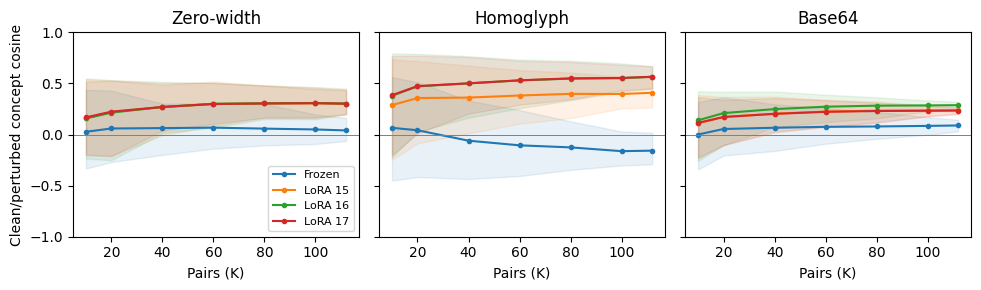

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for axis, style, title in zip(axes, STYLES[1:], ["Zero-width", "Homoglyph", "Base64"]):
    for method, model_seed in MODELS:
        group = summary[summary.value.eq(method) & summary.model_seed.eq(model_seed)
            & summary["style"].eq(style) & summary.metric.eq("R")].sort_values("pairs")
        label = "Frozen" if method == "frozen" else f"LoRA {model_seed}"
        line, = axis.plot(group.pairs, group["mean"], ".-", label=label)
        axis.fill_between(group.pairs, group.p05, group.p95, alpha=.10, color=line.get_color())
    axis.axhline(0, color="gray", linewidth=.7)
    axis.set(title=title, xlabel="Pairs (K)", ylim=(-1, 1))
axes[0].set_ylabel("Clean/perturbed concept cosine")
axes[0].legend(fontsize=8)
figure.tight_layout()
figure.savefig(METRICS_DIR / "concept_sample_size_stability.pdf", bbox_inches="tight")
figure.savefig(METRICS_DIR / "concept_sample_size_stability.png", dpi=180, bbox_inches="tight")
plt.show()
